# Sample-informed preconditioning of PMALA

The Laplace-preconditioned MALA of `mcmc_laplace.ipynb` uses $\mathcal N(m_\mathrm{MAP}, \Gamma)$, $\Gamma = \Gamma_0 - V D V^T$, with the Gauss-Newton Hessian at **one** point. For the nonlinear eikonal forward map, the posterior is wider than that in the stiff directions (the leading eigenvectors of the misfit Hessian) and the coefficients are coupled, so the chain crawls along them although the proposals are accepted: the autocorrelation time of the leading coefficients is thousands of samples (`261026_synthetic_chain_projection`).

This notebook builds a **frozen, sample-informed preconditioner** (in the spirit of DILI, Cui, Law and Marzouk 2016):

1. Take a *pilot chain* of the same posterior (here the Laplace-preconditioned chain of `mcmc_laplace.ipynb`).
2. Project it onto the leading $k$ eigenvectors of the Laplace approximation, $c_i = v_i^T\Gamma_0^{-1}(u - m_\mathrm{MAP})$. Under the Laplace approximation the $c_i$ are independent with variance $1/(1+\lambda_i)$; the chain gives their actual covariance $\Sigma$, including the coupling.
3. Replace the covariance of the approximation in the span of the $k$ eigenvectors by a regularized $\Sigma$ and keep the prior covariance in the complement: $\Gamma_\mathrm{cal} = \Gamma_0 + V_k(\Sigma - I)V_k^T - (\text{Laplace part beyond } k)$. This is again a `LowRankGaussian` (rotated eigenvectors, eigenvalues $1/s_j - 1$ for the principal variances $s_j$ of $\Sigma$; a variance above the prior one cannot be represented and is cut off).
4. Sample with PMALA preconditioned by $\Gamma_\mathrm{cal}$, which is fixed during the chain, so the chain still targets the posterior whatever the pilot was. The result can serve as the pilot of the next round.

**The mean.** `PMALA` states the potential relative to a centred reference measure: the *prior* mean is moved into the potential (`MeanTiltedTargetMeasure`), and the mean of the preconditioner is never read (it cancels from the drift). So the calibration changes only the covariance, and nothing depends on whether the prior mean is zero. `CalibrationSettings.recenter` moves the mean of the Gaussian to the pilot mean, which matters for `PCN_PRECONDITIONED` only.

The same functionality as a non-interactive run is `single_runs.mcmc_calibrated.CalibratedMcmcRun` (`bayes_cep.laplace.calibration` holds the calibration). Every chain step needs a forward and an adjoint solve, so the chains here are short and the effective sample sizes small: the comparison at the end is indicative.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import zarr
from ls_bayesian.common.logging import BaseLogger, LoggerSettings
from ls_bayesian.lowrank.eigensolvers import RandomizedDoublePassSolver
from ls_bayesian.mcmc.sampler import SamplerSettings

from bayes_cep.laplace.builder import LaplaceBuilder, LaplaceSettings
from bayes_cep.laplace.calibration import (
    CalibrationSettings,
    calibrate_approximation,
    estimate_subspace_moments,
)
from bayes_cep.laplace.reference_covariance import PriorReferenceCovariance
from bayes_cep.mcmc.builder import (
    SAMPLE_STORE_NAME,
    MCMCAlgorithmName,
    MCMCBuilder,
    MCMCSettings,
    ZarrStorageSettings,
)
from bayes_cep.mcmc.measures import LowRankGaussianMeasure
from bayes_cep.mesh.interpolation import NearestNeighborInterpolationStrategy
from bayes_cep.mesh.io import load_pyvista_mesh
from bayes_cep.posterior.builder import PosteriorBuilder, PosteriorSettings
from bayes_cep.posterior.likelihood import LikelihoodSettings
from single_runs.chain_projection import compute_autocorrelation_time
from single_runs.data import PreprocessedData
from single_runs.reference import reference_eikonal_settings, reference_prior_parameters

DATA_DIR = Path.cwd().parent / "example_data"
RAW_DIR = DATA_DIR / "raw"
PREPROCESSING_DIR = DATA_DIR / "preprocessing"
MAP_DIR = DATA_DIR / "map"
WORK_DIR = Path.cwd().parent / "working_data" / "mcmc_calibrated_notebook"  # gitignored

## Settings

- `NUM_EIGENVALUES`, `STEP_WIDTH`: rank of the Laplace approximation and the $\delta$ of PMALA, as in `mcmc_laplace.ipynb`. The calibrated chain uses the same $\delta$, so the comparison isolates the preconditioner.
- `PILOT_PATHS`: Zarr stores of finished chains of this posterior, pooled. The default is the chain `mcmc_laplace.ipynb` writes; if it is not there, a pilot chain of `PILOT_NUM_SAMPLES` Laplace-preconditioned steps is run first.
- `START`: the state the calibrated chain starts at. Any start is valid and only changes the burn-in. The MAP estimate is far from the bulk of the posterior in the stiff directions (the chain sits many Laplace standard deviations away), the last state of the pilot chain is already in the typical set, and the pilot mean is a single point that can lie off the high-density region of a curved posterior: the cell before the sampler prints the potentials of these candidates.
- `CalibrationSettings`: `num_coefficients` is the number $k$ of stiff directions that are recalibrated (the slowest ones); `burn_in` and `thinning` act on each pilot chain; `coupling_shrinkage` moves the covariance towards its diagonal (0 keeps the coupling, 1 drops it); `variance_inflation` multiplies it, against the bias of a short pilot chain, whose slow directions are under-explored; `minimum_variance_ratio = 1` never lets the calibration be narrower than the Laplace approximation.

In [2]:
NUM_EIGENVALUES = 800
OVERSAMPLING = 20
MINIMUM_EIGENVALUE = 1e-6
STEP_WIDTH = 0.01

PILOT_PATHS = [DATA_DIR / "mcmc_laplace_notebook" / SAMPLE_STORE_NAME]
PILOT_NUM_SAMPLES = 1000  # only used when a pilot chain has to be run

CALIBRATION = CalibrationSettings(
    num_coefficients=100,
    burn_in=100,
    thinning=1,
    block_size=500,
    coupling_shrinkage=0.2,
    variance_inflation=1.0,
    minimum_variance_ratio=1.0,
    recenter=False,
)

NUM_SAMPLES = 1000
SEED = 1
START = "pilot_last"  # where the calibrated chain starts: "map", "pilot_last" or "pilot_mean"
RUN_SAMPLER = True

## Posterior and Laplace approximation

As in `mcmc_laplace.ipynb`: the data of the single retained patient, the posterior, and the Laplace approximation at the MAP estimate. `components.prior` provides the prior precision $\Gamma_0^{-1}$, which the coefficients need.

In [3]:
mesh = load_pyvista_mesh(RAW_DIR / "mesh.vtu")
basis_vectors = np.load(RAW_DIR / "basis_vecs.npy")
data = PreprocessedData.load(PREPROCESSING_DIR)
map_estimate = np.load(MAP_DIR / "map_estimate.npy")

components = PosteriorBuilder(
    PosteriorSettings(
        mesh=mesh,
        basis_vectors=basis_vectors,
        prior_mean_vector=data.prior_mean,
        prior_parameters=reference_prior_parameters(),
        eikonal_settings=reference_eikonal_settings(),
        likelihood_settings=LikelihoodSettings(
            num_vertices=mesh.n_points,
            observed_vertex_indices=data.observed_vertex_indices,
            data_vector=data.observed_activation_times,
            noise_variance=data.noise_variance,
        ),
    ),
    interpolation_strategy=NearestNeighborInterpolationStrategy(),
).build_components()
log_posterior = components.to_log_posterior()
prior = components.prior

laplace_settings = LaplaceSettings(
    eigensolver=RandomizedDoublePassSolver(oversampling=OVERSAMPLING, seed=0),
    num_eigenvalues=NUM_EIGENVALUES,
    minimum_eigenvalue=MINIMUM_EIGENVALUE,
    sample_seed=0,
)
laplace = LaplaceBuilder(laplace_settings, components).build(map_estimate)
eigenvalues = laplace.eigenpairs.eigenvalues
eigenvectors = laplace.eigenpairs.eigenvectors
print(f"{mesh.n_points} vertices; kept {eigenvalues.size} of {NUM_EIGENVALUES} eigenpairs")
print(f"eigenvalues from {eigenvalues[0]:.3e} down to {eigenvalues[-1]:.3e}")

15820 vertices; kept 774 of 800 eigenpairs
eigenvalues from 1.088e+06 down to 1.446e-02


## Helper: run a PMALA chain

`run_chain(approximation, directory, num_samples, seed, prefix, initial_state)` samples with PMALA preconditioned by a `LowRankGaussian` and writes the Zarr store to `directory` (overwritten).

In [4]:
def run_chain(approximation, directory, num_samples, seed, prefix, initial_state):
    directory.mkdir(parents=True, exist_ok=True)
    builder = MCMCBuilder(
        MCMCSettings(
            algorithm=MCMCAlgorithmName.PMALA,
            step_width=STEP_WIDTH,
            storage=ZarrStorageSettings(chunk_size=100),
        ),
        log_posterior,
        output_dir=directory,
        approximation=LowRankGaussianMeasure(approximation),
    )
    with BaseLogger(LoggerSettings(), prefix=prefix) as logger:
        sampler = builder.build(logger=logger)
        sampler.run(
            initial_state=initial_state,
            settings=SamplerSettings(num_samples=num_samples, log_interval=100),
            seed=seed,
        )
    acceptance = float(builder.outputs[0].all_values[-1])
    print(f"final acceptance rate {acceptance:.3f}")
    return acceptance

## Pilot chain

The pilot is a chain of the same posterior; the Laplace-preconditioned chain of `mcmc_laplace.ipynb` is used if it exists. Its length and quality limit the calibration: the stiffest coefficients have an autocorrelation time of hundreds of samples or more, so a short pilot gives noisy covariances for exactly the directions that matter (hence `variance_inflation` and the second round at the end).

In [5]:
missing = [path for path in PILOT_PATHS if not path.exists()]
if missing:
    print(f"no pilot chain at {missing[0]}: running {PILOT_NUM_SAMPLES} Laplace-preconditioned steps")
    pilot_dir = WORK_DIR / "pilot"
    run_chain(laplace.gaussian, pilot_dir, PILOT_NUM_SAMPLES, 0, "pilot", map_estimate)
    PILOT_PATHS = [pilot_dir / SAMPLE_STORE_NAME]
pilot_chains = [zarr.open_group(path, mode="r")["data"] for path in PILOT_PATHS]
for path, chain in zip(PILOT_PATHS, pilot_chains, strict=True):
    print(f"{path}: {chain.shape[0]} samples of {chain.shape[1]} vertices")

/home/max/4-Code/bayes-cep/example_data/mcmc_laplace_notebook/samples.zarr: 1000 samples of 15820 vertices


## Moments of the leading coefficients

`estimate_subspace_moments` streams over the pilot chains (after the burn-in, every `thinning`-th sample) for the mean of the states and the mean and covariance of the coefficients $c_i = v_i^T\Gamma_0^{-1}(u - m_\mathrm{MAP})$ of the first $k$ eigenvectors. It needs $\Gamma_0^{-1}V_k$, one application of the prior precision per eigenvector.

In [6]:
num_coefficients = min(CALIBRATION.num_coefficients, eigenvalues.size)
weighted_eigenvectors = np.stack(
    [prior.apply_precision_operator(vector) for vector in eigenvectors[:, :num_coefficients].T],
    axis=1,
)
moments = estimate_subspace_moments(pilot_chains, weighted_eigenvectors, map_estimate, CALIBRATION)
print(f"{moments.num_samples[0]} pilot samples used")

900 pilot samples used


## Laplace variance against the chain

For each coefficient: the variance in the pilot chain over the Laplace variance $1/(1+\lambda_i)$, against the eigenvalue. A ratio of one means the Laplace approximation is right in that direction; the stiff directions (large $\lambda$) are expected above one. The mean of the coefficient in units of its Laplace standard deviation shows how far the chain sits from the MAP estimate. The right panel is the correlation of the first 30 coefficients: the Laplace approximation has none.

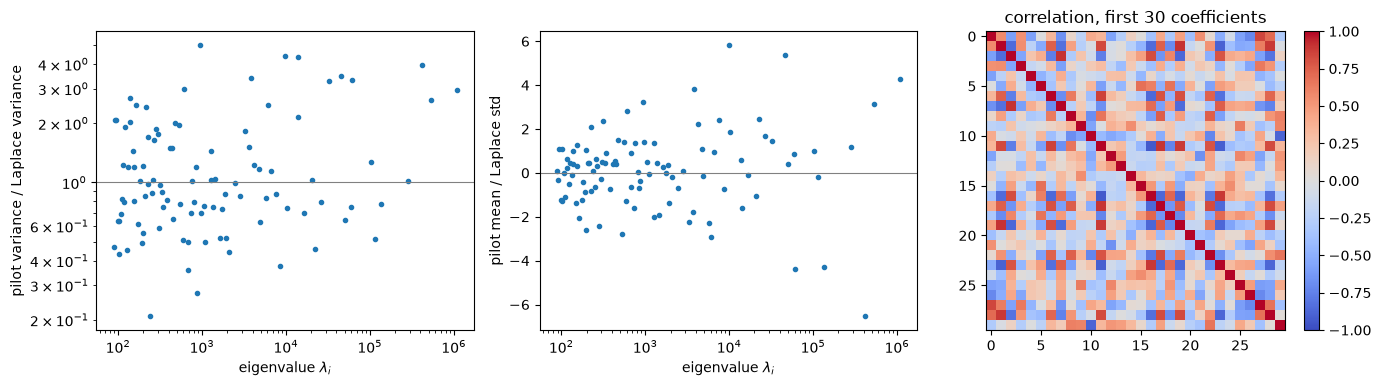

In [7]:
laplace_variances = 1.0 / (1.0 + eigenvalues[:num_coefficients])
empirical_variances = np.diag(moments.coefficient_covariance)
z_scores = moments.coefficient_mean / np.sqrt(laplace_variances)

fig, (ratio_axis, mean_axis, coupling_axis) = plt.subplots(1, 3, figsize=(14, 3.8))
ratio_axis.loglog(eigenvalues[:num_coefficients], empirical_variances / laplace_variances, ".")
ratio_axis.axhline(1.0, color="gray", linewidth=0.8)
ratio_axis.set_xlabel("eigenvalue $\\lambda_i$")
ratio_axis.set_ylabel("pilot variance / Laplace variance")
mean_axis.semilogx(eigenvalues[:num_coefficients], z_scores, ".")
mean_axis.axhline(0.0, color="gray", linewidth=0.8)
mean_axis.set_xlabel("eigenvalue $\\lambda_i$")
mean_axis.set_ylabel("pilot mean / Laplace std")
standard_deviations = np.sqrt(empirical_variances[:30])
correlation = moments.coefficient_covariance[:30, :30] / np.outer(standard_deviations, standard_deviations)
image = coupling_axis.imshow(correlation, vmin=-1, vmax=1, cmap="coolwarm")
coupling_axis.set_title("correlation, first 30 coefficients")
fig.colorbar(image, ax=coupling_axis)
fig.tight_layout()

## Calibrated approximation

`calibrate_approximation` regularizes $\Sigma$ (shrinkage of the coupling, inflation, lower bound relative to the Laplace covariance, cut-off at the prior variance) and returns the `LowRankGaussian` with the eigenpairs rotated into the principal axes of $\Sigma$. The covariance is checked in the coefficient basis: $V_k^T\Gamma_0^{-1}\Gamma_\mathrm{cal}\Gamma_0^{-1}V_k$ must equal the regularized $\Sigma$.

0 principal variances cut off at the prior variance
variance / Laplace variance: pilot median 0.98, max 5.01; calibrated median 1.60, max 5.08


covariance in the coefficient basis equals the regularized one: True


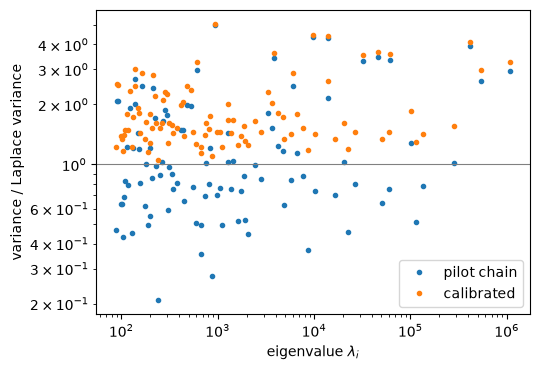

In [8]:
calibrated = calibrate_approximation(
    laplace,
    PriorReferenceCovariance(prior),
    moments,
    CALIBRATION,
    seed=laplace_settings.sample_seed,
)
gaussian = calibrated.approximation.gaussian
print(f"{calibrated.num_clipped} principal variances cut off at the prior variance")
print(
    "variance / Laplace variance: pilot median "
    f"{np.median(calibrated.empirical_variance_ratios):.2f}, max "
    f"{np.max(calibrated.empirical_variance_ratios):.2f}; calibrated median "
    f"{np.median(calibrated.calibrated_variance_ratios):.2f}, max "
    f"{np.max(calibrated.calibrated_variance_ratios):.2f}"
)

check = np.stack(
    [
        weighted_eigenvectors.T @ gaussian.apply_covariance_operator(weighted_eigenvectors @ column)
        for column in np.eye(num_coefficients)[:, :5].T
    ],
    axis=1,
)
print(
    "covariance in the coefficient basis equals the regularized one: "
    f"{np.allclose(check, calibrated.calibrated_covariance[:, :5], atol=1e-8)}"
)

fig, axis = plt.subplots(figsize=(5.5, 3.8))
axis.loglog(eigenvalues[:num_coefficients], calibrated.empirical_variance_ratios, ".", label="pilot chain")
axis.loglog(eigenvalues[:num_coefficients], calibrated.calibrated_variance_ratios, ".", label="calibrated")
axis.axhline(1.0, color="gray", linewidth=0.8)
axis.set_xlabel("eigenvalue $\\lambda_i$")
axis.set_ylabel("variance / Laplace variance")
axis.legend()
fig.tight_layout()

## Where to start

The negative log posterior (a likelihood and a prior evaluation, one forward solve each) at the candidate starts, and at a few states of the pilot chain after its burn-in for comparison. A candidate whose potential lies far above those of the pilot states is not in the typical set.

In [9]:
def potential(state):
    return log_posterior.evaluate_likelihood_cost(state) + log_posterior.evaluate_prior_cost(state)


pilot_states = np.asarray(
    pilot_chains[0].get_orthogonal_selection(
        (np.linspace(CALIBRATION.burn_in, pilot_chains[0].shape[0] - 1, 6).astype(int), slice(None))
    )
)
print(f"MAP estimate: {potential(map_estimate):.1f}")
print(f"pilot mean:   {potential(moments.mean):.1f}")
print("pilot states: " + ", ".join(f"{potential(state):.1f}" for state in pilot_states))
initial_states = {"map": map_estimate, "pilot_last": pilot_states[-1], "pilot_mean": moments.mean}

MAP estimate: 558.3


pilot mean:   2428.3


pilot states: 6931.0, 8391.2, 8511.7, 8534.1, 8362.6, 8317.0


## Run the calibrated chain

The same PMALA and step width as the pilot, with the calibrated Gaussian as preconditioner. The calibration is fixed from here on. **Note:** every step needs a forward and an adjoint solve, about one to two seconds; `RUN_SAMPLER = False` reads the chain of an earlier run from `WORK_DIR`.

In [10]:
CALIBRATED_DIR = WORK_DIR / "calibrated"
if RUN_SAMPLER:
    calibrated_acceptance = run_chain(
        gaussian, CALIBRATED_DIR, NUM_SAMPLES, SEED, "calibrated", initial_states[START]
    )
calibrated_chain = zarr.open_group(CALIBRATED_DIR / SAMPLE_STORE_NAME, mode="r")["data"]
print(f"calibrated chain: {calibrated_chain.shape[0]} samples")

[CALIBRATED]  Iteration     Time [s] mean of acceptance mean         mean of mean


[CALIBRATED] --------------------------------------------------------------------


[CALIBRATED]          0        0.020 +1.000e+00         -1.144e-01   -1.144e-01  


[CALIBRATED]        100       97.393 +5.842e-01         -1.166e-01   -1.145e-01  


[CALIBRATED]        200      196.993 +5.771e-01         -1.169e-01   -1.168e-01  


...

[CALIBRATED]        600      590.464 +6.007e-01         -1.114e-01   -1.139e-01  


[CALIBRATED]        700      689.077 +5.892e-01         -1.095e-01   -1.135e-01  


[CALIBRATED]        800      787.323 +5.793e-01         -1.082e-01   -1.129e-01  


[CALIBRATED]        900      890.672 +5.771e-01         -1.130e-01   -1.127e-01  


final acceptance rate 0.568
calibrated chain: 1000 samples


## Comparison in the coefficients

The leading coefficients of the pilot (Laplace-preconditioned) chain and of the calibrated chain, in units of the Laplace standard deviation of each: traces of the first four, and the integrated autocorrelation time of each of the first 30 (initial monotone sequence estimator of Geyer, no cap on the lag). The chains are short, so the times are rough and limited by the chain length; read the ratio between the two chains, not the values. The pilot chain started at the MAP estimate and the calibrated chain at `START`, both after the same burn-in, with different seeds.

median time over the first 30: pilot 189, calibrated 177
largest time: pilot 318, calibrated 297


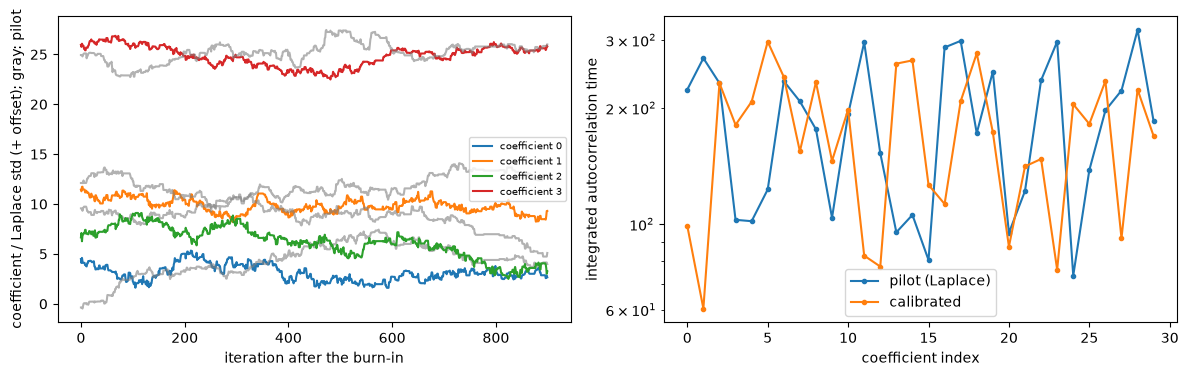

In [11]:
BURN_IN = 100
NUM_COMPARED = 30


def coefficients_of(chain):
    states = np.asarray(chain[BURN_IN:]) - map_estimate
    return states @ weighted_eigenvectors[:, :NUM_COMPARED] / np.sqrt(laplace_variances[:NUM_COMPARED])


pilot_coefficients = coefficients_of(pilot_chains[0])
calibrated_coefficients = coefficients_of(calibrated_chain)
pilot_times, _ = compute_autocorrelation_time(pilot_coefficients, (1,))
calibrated_times, _ = compute_autocorrelation_time(calibrated_coefficients, (1,))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for index in range(4):
    axes[0].plot(calibrated_coefficients[:, index] + 8 * index, label=f"coefficient {index}")
    axes[0].plot(pilot_coefficients[:, index] + 8 * index, color="gray", alpha=0.6)
axes[0].set_xlabel("iteration after the burn-in")
axes[0].set_ylabel("coefficient / Laplace std (+ offset); gray: pilot")
axes[0].legend(fontsize=7)
axes[1].semilogy(pilot_times, ".-", label="pilot (Laplace)")
axes[1].semilogy(calibrated_times, ".-", label="calibrated")
axes[1].set_xlabel("coefficient index")
axes[1].set_ylabel("integrated autocorrelation time")
axes[1].legend()
fig.tight_layout()

print(f"median time over the first {NUM_COMPARED}: pilot {np.nanmedian(pilot_times):.0f}, calibrated {np.nanmedian(calibrated_times):.0f}")
print(f"largest time: pilot {np.nanmax(pilot_times):.0f}, calibrated {np.nanmax(calibrated_times):.0f}")

## Does the new chain agree with the calibration?

If the calibrated chain explores more than the pilot did, its variances exceed the calibrated ones in the directions where the pilot under-explored them, and a second round with the new chain added to `PILOT_PATHS` improves the estimate. A new chain whose variances stay close to the calibrated ones, with a much shorter autocorrelation time, says the preconditioner matches the posterior there.

median 0.49, largest 4.02


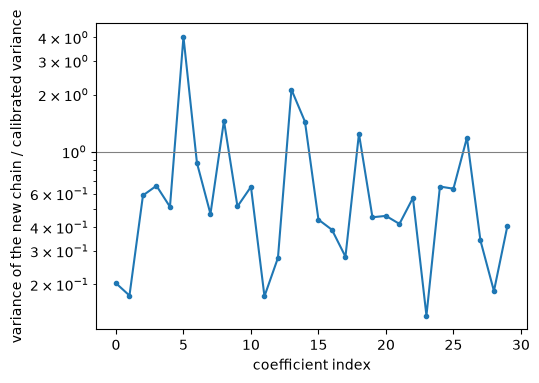

In [12]:
new_variances = calibrated_coefficients.var(axis=0, ddof=1) * laplace_variances[:NUM_COMPARED]
used_variances = np.diag(calibrated.calibrated_covariance)[:NUM_COMPARED]
fig, axis = plt.subplots(figsize=(5.5, 3.8))
axis.semilogy(new_variances / used_variances, ".-")
axis.axhline(1.0, color="gray", linewidth=0.8)
axis.set_xlabel("coefficient index")
axis.set_ylabel("variance of the new chain / calibrated variance")
fig.tight_layout()
print(f"median {np.median(new_variances / used_variances):.2f}, largest {np.max(new_variances / used_variances):.2f}")

## Next round and the non-interactive run

For a second round, append the calibrated chain to the pilots and rerun from the moments cell:

```python
PILOT_PATHS = [*PILOT_PATHS, CALIBRATED_DIR / SAMPLE_STORE_NAME]
```

The pilots are pooled, so their between-chain variation enters the covariance. For long chains on the cluster use `single_runs.mcmc_calibrated.CalibratedMcmcRun` (`CalibratedMcmcRunConfig` is the config of `PreconditionedMcmcRun` plus `calibration` and `pilot_chain_paths`): it reads the stores of the pilot chains, computes the eigenpairs and the calibration itself, and writes the calibration (`calibrated_covariance.npy`, `pilot_coefficient_covariance.npy`, ...) next to its chain, so its chain is the pilot of the next round.